# TP 5 : Réduction de dimension (ACP, t-SNE, UMAP)

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 5 :** Réduction de dimension et visualisation  
**Auteur :** Étudiant en informatique / Data Science  
**Graine aléatoire :** seed = 42

---

## Objectifs du TP

L'atelier connecté produit de nombreuses variables capteurs (température, courant, cadence, vibrations et harmoniques spectrales).  
Dans ce cinquième TP, mon objectif est d'explorer et de comparer les méthodes de réduction de dimension :
1. Diagnostiquer la redondance et la colinéarité des 9 variables par matrice de corrélation.
2. Réaliser une ACP (Analyse en Composantes Principales), tracer le diagramme des éboulis et choisir le nombre d'axes.
3. Interpréter physiquement les axes principaux via les charges (loadings) et le cercle des corrélations.
4. Visualiser la projection des régimes de fonctionnement dans le plan PC1-PC2.
5. Appliquer t-SNE avec différentes perplexités, mesurer la fidélité locale (trustworthiness) et analyser ses limites géométriques.
6. Comparer avec UMAP pour la préservation de la structure globale.
7. Construire un pipeline scikit-learn (standardisation + ACP + K-means) et comparer la segmentation dans différents espaces.
8. Revenir aux grandeurs physiques d'origine et formuler les règles de bonne pratique.


## 0. Environnement et préparation des données (9 variables)

Je charge `atelier_connecte.csv` et je sélectionne les 9 variables continues du procédé et du spectre vibratoire :
`variables = ["temperature", "vibration", "courant", "cadence", "vibration_pic", "vib_f1", "vib_f2", "vib_f3", "vib_f4"]`.  
J'impute les valeurs manquantes par la médiane et je standardise avec `StandardScaler()`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


In [2]:
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)
print(f"Dataset charge : {df.shape[0]} lignes et {df.shape[1]} colonnes")

variables = [
    "temperature", "vibration", "courant", "cadence",
    "vibration_pic", "vib_f1", "vib_f2", "vib_f3", "vib_f4"
]

# Imputation et standardisation
imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(df[variables])

scaler = StandardScaler()
X_std = scaler.fit_transform(X_raw)

print(f"Matrice standardisee X_std : {X_std.shape[0]} observations, {X_std.shape[1]} variables")


Dataset charge : 1728 lignes et 20 colonnes
Matrice standardisee X_std : 1728 observations, 9 variables


---
## 1. Diagnostic de redondance (matrice de corrélation)

Je calcule la matrice de corrélation linéaire entre les 9 variables pour identifier les fortes redondances d'information.


In [3]:
corr_matrix = pd.DataFrame(X_raw, columns=variables).corr()

# Paires avec correlation absolue superieure a 0.90
paires_fortes = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        v1, v2 = variables[i], variables[j]
        r = corr_matrix.loc[v1, v2]
        if abs(r) > 0.90:
            paires_fortes.append({"Variable 1": v1, "Variable 2": v2, "Correlation r": round(r, 3)})

df_paires = pd.DataFrame(paires_fortes)
print("Paires de variables ayant |r| > 0.90 :")
df_paires


Paires de variables ayant |r| > 0.90 :


,Variable 1,Variable 2,Correlation r
0,vibration,vibration_pic,0.966
1,vibration,vib_f1,0.931
2,vibration,vib_f2,0.930
3,vibration_pic,vib_f1,0.948
4,vibration_pic,vib_f2,0.942
5,vibration_pic,vib_f3,0.908
6,vib_f1,vib_f2,0.909


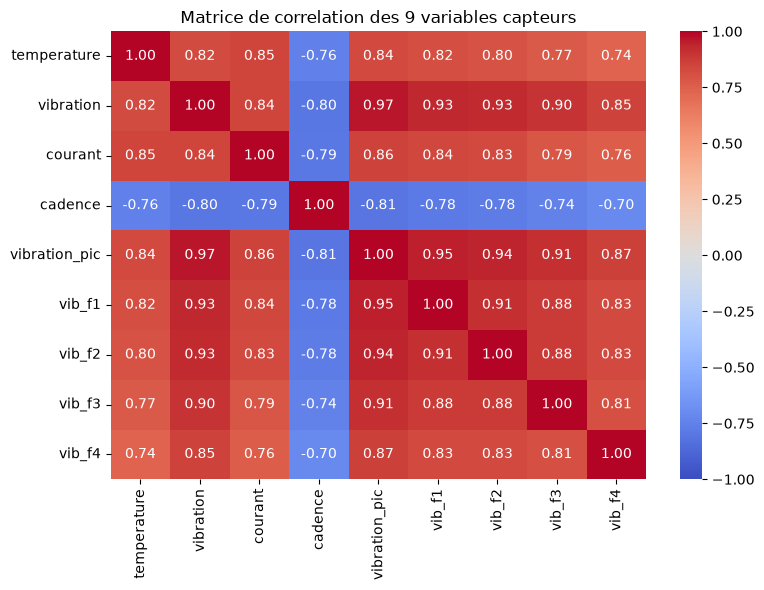

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de correlation des 9 variables capteurs")
plt.tight_layout()
plt.show()


### Que déduit-on pour l'ACP ?

On observe 7 paires de variables dont la corrélation dépasse 0.90, toutes concentrées autour des grandeurs vibratoires :
- `vibration` et `vibration_pic` ont une corrélation presque parfaite (r = 0.966).
- `vibration_pic` est très fortement corrélée aux harmoniques `vib_f1` (0.948), `vib_f2` (0.942) et `vib_f3` (0.908).
- `vibration` globale est également très liée à `vib_f1` (0.931) et `vib_f2` (0.930).

Cette forte colinéarité indique qu'une grande part de l'information portée par les 9 capteurs est redondante. Une ACP est donc particulièrement adaptée : elle va pouvoir comprimer ces signaux liés sans perte majeure d'information en projetant le nuage sur un très petit nombre d'axes orthogonaux.


---
## 2. ACP et diagramme des éboulis

J'ajuste une ACP complète (`PCA(n_components=9)`) sur les 9 variables standardisées `X_std`.  
Sur des données centrées-réduites, la variance totale est égale au nombre de variables (9.0). Chaque valeur propre mesure la variance captée par l'axe correspondant.


In [5]:
pca = PCA(n_components=9, random_state=SEED)
pca.fit(X_std)

val_propres = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_ * 100
var_cumul = np.cumsum(var_ratio)

df_eboulis = pd.DataFrame({
    "Axe": [f"PC{i+1}" for i in range(9)],
    "Valeur propre": val_propres,
    "Variance (%)": var_ratio,
    "Variance cumulee (%)": var_cumul
})
df_eboulis.round(2)


,Axe,Valeur propre,Variance (%),Variance cumulee (%)
0,PC1,7.710,85.570,85.570
1,PC2,0.370,4.150,89.720
2,PC3,0.250,2.800,92.520
3,PC4,0.210,2.340,94.860
4,PC5,0.150,1.650,96.510
5,PC6,0.130,1.460,97.970
6,PC7,0.090,1.000,98.970
7,PC8,0.060,0.700,99.670
8,PC9,0.030,0.330,100.000


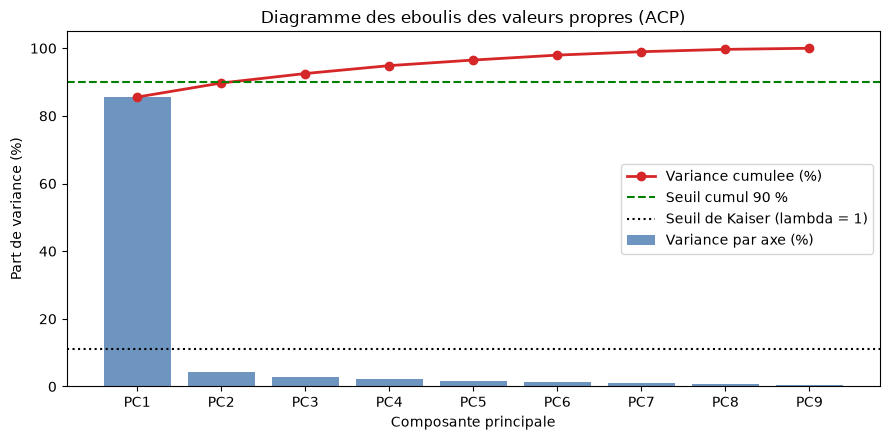

In [6]:
plt.figure(figsize=(9, 4.5))
x_pos = np.arange(1, 10)

plt.bar(x_pos, var_ratio, color="#4a7bb0", alpha=0.8, label="Variance par axe (%)")
plt.plot(x_pos, var_cumul, color="#d62728", marker="o", linewidth=2, label="Variance cumulee (%)")

plt.axhline(90.0, color="green", linestyle="--", label="Seuil cumul 90 %")
plt.axhline(100 * 1.0 / 9.0, color="black", linestyle=":", label="Seuil de Kaiser (lambda = 1)")

plt.title("Diagramme des eboulis des valeurs propres (ACP)")
plt.xlabel("Composante principale")
plt.ylabel("Part de variance (%)")
plt.xticks(x_pos, [f"PC{i}" for i in x_pos])
plt.legend()
plt.tight_layout()
plt.show()


### Combien de composantes principales retenir ?

1. **Règle du seuil cumulé à 90 % :**
   - PC1 capte à elle seule 85.57 % de la variance totale.
   - PC1 + PC2 cumulent 89.72 % de la variance.
   - En ajoutant PC3 (2.80 %), on atteint **92.52 %** de variance cumulée.
   - Selon ce critère, on retient donc **3 composantes**.
2. **Règle de Kaiser (valeur propre supérieure à 1) :**
   - Sur données standardisées, la variance moyenne par variable est de 1.0. Un axe n'est informatif que si sa valeur propre dépasse 1.0.
   - Ici, seule PC1 dépasse largement 1.0 (valeur propre de 7.71). PC2 vaut 0.37 car la redondance vibratoire a presque tout concentré sur le premier axe.
   - Néanmoins, en maintenance industrielle, on retient souvent PC2 et PC3 car elles portent des signaux faibles mais critiques (les signatures harmoniques d'usure de roulement).


---
## 3. Interprétation des axes (charges et cercle des corrélations)

Les charges factorielles (loadings) correspondent à la corrélation entre chaque variable d'origine et chaque axe principal :
`charge(variable, axe) = composante * racine_carree(valeur_propre)`.


In [7]:
loadings = pca.components_[:3].T * np.sqrt(val_propres[:3])
df_loadings = pd.DataFrame(loadings, index=variables, columns=["PC1", "PC2", "PC3"])
print("Charges factorielles (loadings) pour PC1, PC2 et PC3 :")
df_loadings.round(3)


Charges factorielles (loadings) pour PC1, PC2 et PC3 :


,PC1,PC2,PC3
temperature,0.887,-0.269,0.301
vibration,0.968,0.103,-0.031
courant,0.908,-0.242,0.151
cadence,-0.859,0.344,0.363
vibration_pic,0.979,0.092,-0.020
vib_f1,0.956,0.090,-0.010
vib_f2,0.951,0.113,-0.027
vib_f3,0.923,0.177,-0.052
vib_f4,0.889,0.232,0.046


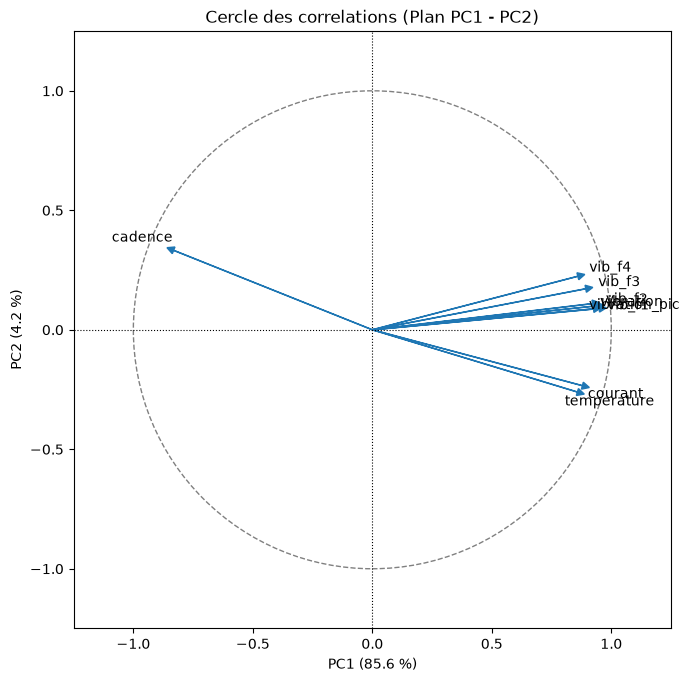

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))

# Cercle unite
cercle = plt.Circle((0, 0), 1.0, color="gray", fill=False, linestyle="--")
ax.add_artist(cercle)

for i, var in enumerate(variables):
    x = df_loadings.loc[var, "PC1"]
    y = df_loadings.loc[var, "PC2"]
    ax.arrow(0, 0, x, y, head_width=0.03, head_length=0.03, color="#1f77b4", length_includes_head=True)
    ax.text(x * 1.12, y * 1.12, var, fontsize=10, ha="center", va="center")

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_title("Cercle des correlations (Plan PC1 - PC2)")
ax.set_xlabel(f"PC1 ({var_ratio[0]:.1f} %)")
ax.set_ylabel(f"PC2 ({var_ratio[1]:.1f} %)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


### Interprétation physique des deux premiers axes

Rappelons que les signes d'une ACP sont arbitraires (une inversion de signe conserve les mêmes propriétés) : on raisonne donc sur les oppositions et les valeurs absolues.

- **PC1 (85.6 % de variance) : axe de niveau de sollicitation globale.**
  Toutes les variables de charge et de coupe sont fortement corrélées positivement à PC1 : `vibration_pic` (0.979), `vibration` (0.968), `courant` (0.908), `temperature` (0.887) et les harmoniques. À l'opposé, la `cadence` est fortement corrélée négativement (-0.859).  
  Cet axe traduit l'effort de coupe : plus une machine produit vite à vide, plus sa cadence est haute et ses vibrations faibles (PC1 négatif) ; plus la machine peine sous l'effort ou vibre sous la charge, plus PC1 est élevé.
- **PC2 (4.1 % de variance) : axe de diagnostic mécanique vs thermique.**
  Cet axe oppose les hautes fréquences vibratoires (`vib_f4` à +0.232, `vib_f3` à +0.177) à la `temperature` (-0.269) et au `courant` (-0.242).  
  Cet axe permet de distinguer un échauffement purement thermique (vers le bas) d'une dégradation mécanique haute fréquence de type roulement (vers le haut).


---
## 4. Projection des relevés dans le plan PC1-PC2

Je projette les 1 728 observations dans le premier plan factoriel (PC1-PC2) en colorant les points selon le diagnostic expert `regime_reference`.


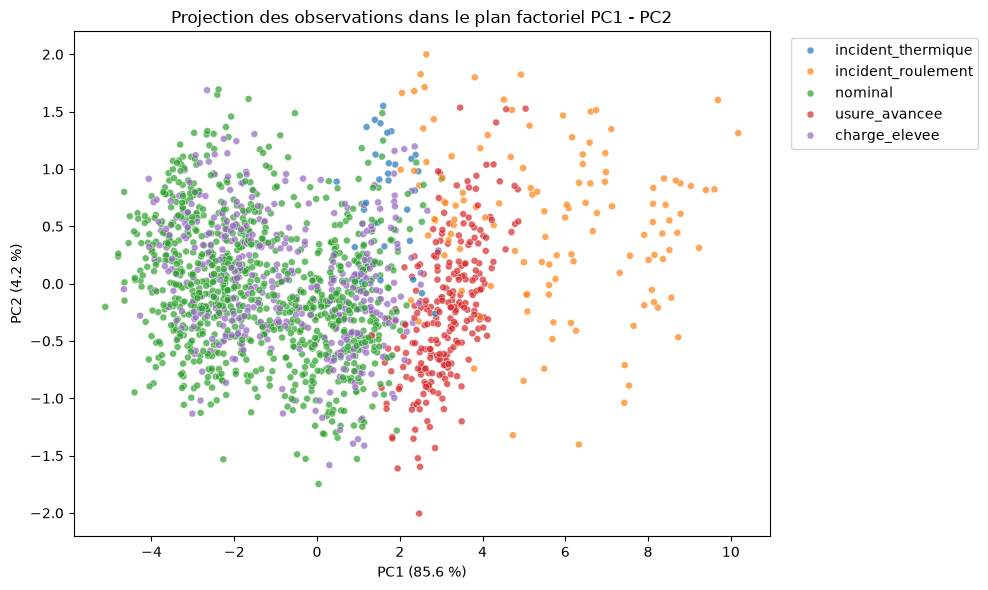

In [9]:
X_pca = pca.transform(X_std)

df_proj = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "regime_reference": df["regime_reference"]
})

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_proj,
    x="PC1", y="PC2",
    hue="regime_reference",
    palette="tab10",
    alpha=0.7,
    s=25
)
plt.title("Projection des observations dans le plan factoriel PC1 - PC2")
plt.xlabel(f"PC1 ({var_ratio[0]:.1f} %)")
plt.ylabel(f"PC2 ({var_ratio[1]:.1f} %)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Commentaire sur la séparation des régimes

- **Régimes bien isolés :**
  Les relevés d'`incident_roulement` se détachent nettement en haut à droite du nuage : ils combinent une forte sollicitation sur PC1 et une valeur positive élevée sur PC2 due aux harmoniques de hautes fréquences `vib_f3` et `vib_f4`.
- **Régimes en continuum :**
  Les états `nominal`, `charge_elevee` et `usure_avancee` s'étalent de gauche à droite de manière continue le long de l'axe PC1. Il n'y a pas de frontière vide entre ces trois régimes, ce qui illustre le continuum physique de marche des machines.


---
## 5. Visualisation non linéaire avec t-SNE

t-SNE est une technique non linéaire qui convertit les distances euclidiennes en probabilités de voisinage et cherche à les reproduire en 2D en minimisant la divergence de Kullback-Leibler.  
J'entraîne t-SNE pour 3 valeurs de perplexité : `p = 5`, `p = 30` et `p = 100`.


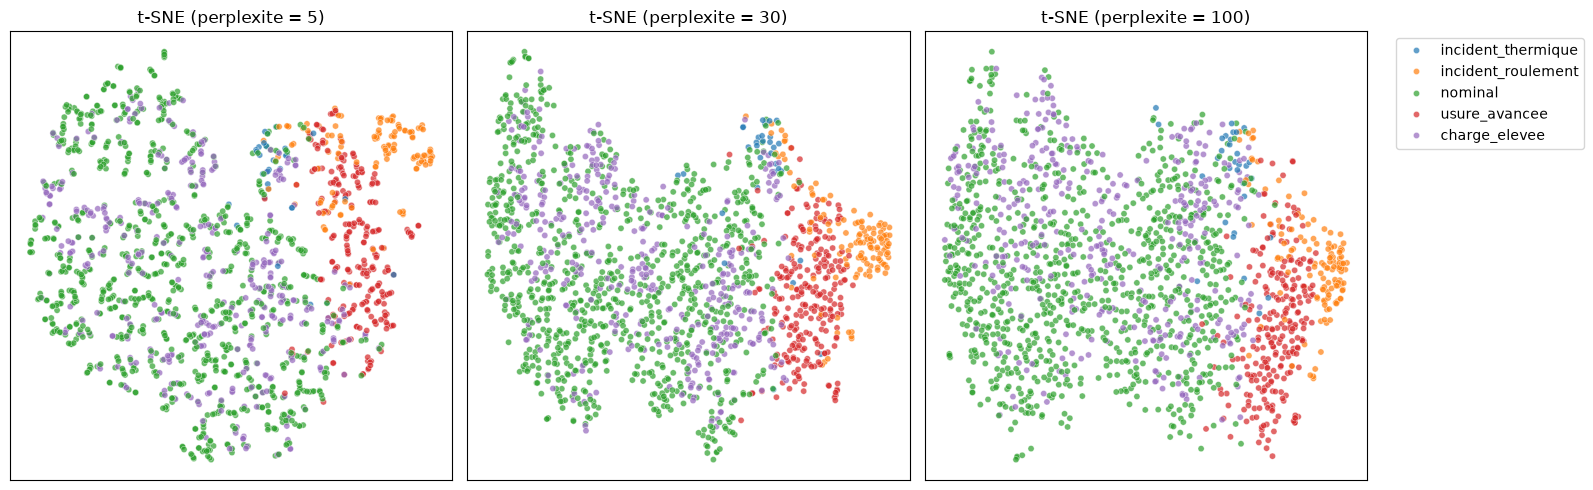

In [10]:
perplexites = [5, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, p in enumerate(perplexites):
    tsne = TSNE(n_components=2, perplexity=p, init="pca", learning_rate="auto", random_state=SEED)
    coords_tsne = tsne.fit_transform(X_std)
    
    sns.scatterplot(
        x=coords_tsne[:, 0], y=coords_tsne[:, 1],
        hue=df["regime_reference"],
        palette="tab10",
        s=20, alpha=0.7,
        ax=axes[idx],
        legend=(idx == 2)
    )
    axes[idx].set_title(f"t-SNE (perplexite = {p})")
    axes[idx].set_xticks([])
    axes[idx].set_yticks([])

if axes[2].get_legend():
    axes[2].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [11]:
# Mesure de la preservation du voisinage local (Trustworthiness a 10 voisins)
trust_pca = trustworthiness(X_std, X_pca[:, :2], n_neighbors=10)
print(f"Trustworthiness ACP 2D        : {trust_pca:.3f}")

for p in perplexites:
    tsne_eval = TSNE(n_components=2, perplexity=p, init="pca", learning_rate="auto", random_state=SEED)
    c_eval = tsne_eval.fit_transform(X_std)
    t_val = trustworthiness(X_std, c_eval, n_neighbors=10)
    print(f"Trustworthiness t-SNE (p={p:3d}) : {t_val:.3f}")


Trustworthiness ACP 2D        : 0.942


Trustworthiness t-SNE (p=  5) : 0.980


Trustworthiness t-SNE (p= 30) : 0.984


Trustworthiness t-SNE (p=100) : 0.978


### Peut-on lire les distances entre amas sur t-SNE ?

**Non, formellement non.**  
- t-SNE optimise la préservation des voisinages locaux (comme le confirme sa forte trustworthiness de 0.984 vs 0.942 pour l'ACP), mais il compresse les espaces vides et distord complètement la géométrie globale.
- La distance apparente entre deux amas sur une carte t-SNE dépend de la perplexité et de l'initialisation : elle n'a aucune proportionnalité avec la distance physique réelle dans l'espace des 9 capteurs.
- Les axes t-SNE n'ont aucune unité physique ni sens statistique : on ne peut ni les interpréter comme des variables ni les graduer.


---
## 6. UMAP (facultatif - avec gestion d'import)

UMAP (Uniform Manifold Approximation and Projection) est une autre méthode non linéaire basée sur la topologie. Contrairement à t-SNE, elle préserve un peu mieux les relations à grande échelle et permet de projeter de nouveaux points via `.transform()`.


In [12]:
try:
    import umap
    print("UMAP est installe. Generation des projections UMAP...")
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    voisins_liste = [5, 15, 50]
    
    for i, n_v in enumerate(voisins_liste):
        u_mod = umap.UMAP(n_neighbors=n_v, min_dist=0.1, random_state=SEED)
        u_coords = u_mod.fit_transform(X_std)
        sns.scatterplot(
            x=u_coords[:, 0], y=u_coords[:, 1],
            hue=df["regime_reference"],
            palette="tab10",
            s=20, alpha=0.7,
            ax=axes[i],
            legend=(i == 2)
        )
        axes[i].set_title(f"UMAP (n_neighbors = {n_v})")
        axes[i].set_xticks([])
        axes[i].set_yticks([])
        
    if axes[2].get_legend():
        axes[2].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Information : le paquet 'umap-learn' n'est pas installe dans cet environnement.")
    print("Cette question etant facultative, la cellule continue sans interrompre le notebook.")


Information : le paquet 'umap-learn' n'est pas installe dans cet environnement.
Cette question etant facultative, la cellule continue sans interrompre le notebook.


---
## 7. Pipeline standardisation + ACP + K-means (k = 4)

Je construis un pipeline scikit-learn complet :
`pipe = make_pipeline(StandardScaler(), PCA(n_components=0.90, random_state=42))`  
Puis j'entraîne K-means (k = 4) dans 3 espaces différents pour comparer leurs performances :
1. Sur les données standardisées complètes sans ACP (9 dimensions).
2. Dans l'espace ACP à 90 % de variance (3 dimensions).
3. Directement sur les coordonnées 2D produites par t-SNE (perversité = 30).


In [13]:
# 1. Dans l'espace brut standardise (9D)
km_9d = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_std)
sil_9d = silhouette_score(X_std, km_9d.labels_)
ari_9d = adjusted_rand_score(df["regime_reference"], km_9d.labels_)

# 2. Dans l'espace ACP (3D retenant 90% de variance)
pipe_pca = make_pipeline(StandardScaler(), PCA(n_components=0.90, random_state=SEED))
Z_pca = pipe_pca.fit_transform(X_raw)
km_pca = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(Z_pca)
sil_pca = silhouette_score(Z_pca, km_pca.labels_)
ari_pca = adjusted_rand_score(df["regime_reference"], km_pca.labels_)

# 3. Sur les coordonnees 2D de t-SNE
tsne_model = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
Z_tsne = tsne_model.fit_transform(X_std)
km_tsne = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(Z_tsne)
sil_tsne = silhouette_score(Z_tsne, km_tsne.labels_)
ari_tsne = adjusted_rand_score(df["regime_reference"], km_tsne.labels_)

tableau_espaces = pd.DataFrame({
    "Espace de clustering": ["Sans ACP (9D standardise)", "Avec ACP (3D, 90 % variance)", "Coordonnees t-SNE 2D"],
    "Dimensions": [9, Z_pca.shape[1], 2],
    "Score de silhouette": [sil_9d, sil_pca, sil_tsne],
    "ARI vs expert": [ari_9d, ari_pca, ari_tsne]
})
tableau_espaces.round(3)


,Espace de clustering,Dimensions,Score de silhouette,ARI vs expert
0,Sans ACP (9D standardise),9,0.379,0.288
1,"Avec ACP (3D, 90 % variance)",3,0.458,0.287
2,Coordonnees t-SNE 2D,2,0.452,0.186


### Que conclure sur la silhouette calculée sur t-SNE ?

- Dans l'espace ACP (3D), la silhouette augmente nettement à **0.458** (contre 0.379 en 9D) tout en conservant le même alignement avec les experts (**ARI = 0.287**). L'ACP a éliminé les dimensions résiduelles de bruit tout en gardant l'information utile.
- Sur les coordonnées t-SNE, la silhouette semble honorable (**0.452**), mais l'ARI s'effondre à **0.186** !  
  C'est un piège classique : t-SNE resserre artificiellement les paquets de points en 2D, ce qui gonfle le calcul de silhouette, mais déforme la structure globale des classes réelles. Il ne faut donc jamais évaluer ni clusteriser sur des coordonnées t-SNE.


---
## 8. Retour aux variables originales et synthèse

Pour rendre les résultats exploitables sur le plan métier, je reprends les clusters obtenus par K-means dans l'espace ACP (3 composantes), je les ordonne par température médiane croissante (0 à 3) et j'affiche leur profil médian dans les **unités d'origine des 9 variables**.


In [14]:
df_final = pd.DataFrame(X_raw, columns=variables)
df_final["cluster_pca"] = km_pca.labels_
df_final["regime_reference"] = df["regime_reference"].values

# Ordonner les clusters par temperature croissante (0 a 3)
temp_meds = df_final.groupby("cluster_pca")["temperature"].median().sort_values()
mapping_ord = {c: i for i, c in enumerate(temp_meds.index)}
df_final["segment"] = df_final["cluster_pca"].map(mapping_ord)

print("Profils medians des 4 segments dans leurs unites physiques d'origine :")
df_final.groupby("segment")[variables].median().round(2)


Profils medians des 4 segments dans leurs unites physiques d'origine :


,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4
segment,,,,,,,,,
0,72.150,1.760,12.020,55.410,2.860,0.710,0.530,0.300,0.150
1,78.930,2.960,15.210,47.750,4.880,1.240,0.900,0.530,0.260
2,83.770,4.110,17.260,42.880,6.850,1.740,1.290,0.750,0.380
3,89.460,6.010,20.270,35.340,10.020,2.630,1.860,1.040,0.570


In [15]:
print("Croisement des 4 segments ACP avec les regimes de reference experts :")
pd.crosstab(df_final["segment"], df_final["regime_reference"], margins=True)


Croisement des 4 segments ACP avec les regimes de reference experts :


regime_reference,charge_elevee,incident_roulement,incident_thermique,nominal,usure_avancee,All
segment,,,,,,
0,189,0,0,525,0,714
1,170,0,12,372,5,559
2,34,46,19,30,245,374
3,0,80,0,0,1,81
All,393,126,31,927,251,1728


### Synthèse : Précautions d'interprétation pour la maintenance

La réduction de dimension est un outil puissant pour simplifier la télémétrie, mais elle exige quatre précautions fondamentales :
Ne confondez jamais une projection visuelle agréable avec une segmentation objective du procédé. N'interprétez jamais les distances entre amas sur une carte t-SNE ou UMAP car ces algorithmes déforment l'espace global pour resserrer les voisinages locaux. Vérifiez toujours la sensibilité des résultats aux hyperparamètres (perplexité, nombre de composantes). Enfin, revenez systématiquement aux grandeurs physiques d'origine dans leurs unités réelles avant de préconiser une action mécanique sur une machine.
